# CartSense: Apriori Recommendation Pipeline

End-to-end ML workflow for the CartSense market-basket system: **raw data → validation → preprocessing → train/test split → feature encoding → model training (Apriori) → evaluation**.

Apriori is an *unsupervised* association-rule method, so there is no label to predict and no classification accuracy. The model is therefore evaluated as a **recommender** on held-out users: one product is hidden from each test order, and we measure whether the rules bring it back (hit rate@K, MRR@K) compared with a popularity baseline.

### Pipeline overview

```
modeldataset.csv
   │  1. load + validate            load_orders()
   │  2. preprocess + build baskets build_order_baskets()      (1 basket = 1 order)
   ▼
 clean order lines
   │  3. user-disjoint split        split_users()              (80% train / 20% test)
   ├──────────────► TRAIN users                      TEST users ◄──────────────┐
   │  4. encode baskets (one-hot)   encode_baskets()                           │
   │  5. (feature scaling: not applicable, see below)                          │
   │  6. train: Apriori + rules     mine_rules()                               │
   ▼                                                                           │
 association rules ───────────────► 7. evaluate (hide 1 item per order) ◄──────┘
                                       evaluate_recommendations()
```

| # | Pipeline stage | ML-course equivalent | Where |
|---|---|---|---|
| 1 | Data ingestion and validation | loading data, sanity checks | `load_orders` |
| 2 | Preprocessing | cleaning, type conversion, missing values, building the model input | `load_orders`, `build_order_baskets` |
| 3 | Train/test split | `train_test_split` (split by **user** to prevent leakage) | `split_users` |
| 4 | Feature encoding | one-hot encoding | `encode_baskets` (`TransactionEncoder`) |
| 5 | Feature scaling | `StandardScaler` | **not applicable**: inputs are boolean item-presence flags |
| 6 | Model training | `model.fit()` | `mine_rules` (`apriori` + `association_rules`) |
| 7 | Evaluation | `model.score()` / metrics vs baseline | `evaluate_recommendations` |
| 8 | Deployment | serving the model | `build_payload` in `cartsense_analysis` (the web app) |

All stages are plain functions chained by `run_pipeline()` (Section 8). An `sklearn.pipeline.Pipeline` is not used because it chains transformers into a supervised estimator with `fit`/`predict` on labels; Apriori has neither labels nor scaling, so an explicit staged pipeline is the natural fit.

## 1. Setup: imports and configuration

All hyperparameters live in one place so every run is reproducible. Change `DATA_PATH` to switch between the 20k, 100k and 1M-row dataset splits.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

# ---- data ----
DATA_PATH = Path("public/dataset/modeldataset.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../public/dataset/modeldataset.csv")

# ---- hyperparameters / experiment settings ----
SEED = 42            # reproducible split and hidden-item sampling
TEST_SIZE = 0.20     # share of USERS held out for testing
MIN_SUPPORT = 0.005  # itemset must appear in at least 0.5% of order baskets
MIN_CONFIDENCE = 0.20
MAX_LEN = 3          # itemsets of up to 3 products (antecedent of up to 2 -> 1 recommendation)
KS = (1, 3, 5, 10)   # recommendation list sizes to evaluate

print("Data file:", DATA_PATH.resolve(), "| exists:", DATA_PATH.exists())

Data file: C:\Users\Administrator\Desktop\cartsense\public\dataset\modeldataset.csv | exists: True


## 2. Stage 1: Data ingestion and validation

Everything is read as text first so that bad values are *detected* rather than silently coerced. A row is rejected when:
- `order_id`, `user_id` or `product_id` is not an integer,
- `product_name` or `department` is empty,
- `order_dow` is outside 0–6 or `order_hour_of_day` is outside 0–23.

Rejected-row counts are kept as a data-quality report instead of being thrown away.

In [2]:
REQUIRED_COLUMNS = {"order_id", "user_id", "product_id", "product_name", "department"}
NUMERIC_COLUMNS = ["order_id", "user_id", "order_number", "order_dow", "order_hour_of_day",
                   "days_since_prior_order", "product_id", "add_to_cart_order", "reordered", "department_id"]


def load_orders(path):
    # Stage 1 + 2a: load, validate, clean. Returns (clean_frame, quality_report).
    raw = pd.read_csv(path, dtype=str, keep_default_na=False)
    missing_columns = sorted(REQUIRED_COLUMNS - set(raw.columns))
    if missing_columns:
        raise ValueError(f"Missing required columns: {', '.join(missing_columns)}")

    valid = pd.Series(True, index=raw.index)
    problems = []

    def reject(mask, column, rule):
        nonlocal valid
        if mask.any():
            problems.append({"column": column, "rule": rule, "rows_rejected": int(mask.sum())})
        valid &= ~mask

    # identifiers must be integers
    for column in ("order_id", "user_id", "product_id"):
        values = pd.to_numeric(raw[column], errors="coerce")
        reject(values.isna() | (values % 1 != 0), column, "must be an integer")

    # names must be present
    for column in ("product_name", "department"):
        reject(raw[column].str.strip().eq(""), column, "is required")

    # optional time fields must be in range when present
    for column, low, high in (("order_dow", 0, 6), ("order_hour_of_day", 0, 23)):
        if column in raw.columns:
            values = pd.to_numeric(raw[column], errors="coerce")
            bad = raw[column].ne("") & (values.isna() | (values % 1 != 0) | (values < low) | (values > high))
            reject(bad, column, f"must be an integer from {low} to {high}")

    # Stage 2a preprocessing: type conversion, trimming, missing-value handling
    clean = raw.loc[valid].copy()
    for column in NUMERIC_COLUMNS:
        clean[column] = pd.to_numeric(clean[column], errors="coerce") if column in clean else np.nan
    clean["product_name"] = clean["product_name"].str.strip()
    clean["department"] = clean["department"].str.strip()
    clean["reordered"] = clean["reordered"].fillna(0).clip(0, 1)

    quality = {
        "source": str(path),
        "total_rows": len(raw),
        "valid_rows": len(clean),
        "invalid_rows": len(raw) - len(clean),
        "problems": problems,
        "missing_values": {c: int(clean[c].isna().sum()) for c in clean.columns if clean[c].isna().any()},
    }
    return clean, quality


frame, quality = load_orders(DATA_PATH)
display(pd.Series({k: quality[k] for k in ("total_rows", "valid_rows", "invalid_rows")}, name="rows"))
print("Rejected-row breakdown:")
display(pd.DataFrame(quality["problems"]) if quality["problems"] else "none, every row passed validation")
print("Missing values kept as NaN (optional columns):", quality["missing_values"] or "none")

total_rows      999980
valid_rows      999980
invalid_rows         0
Name: rows, dtype: int64

Rejected-row breakdown:


'none, every row passed validation'

Missing values kept as NaN (optional columns): {'days_since_prior_order': 61339}


In [3]:
# sanity checks on the cleaned data (fail loudly if the loader let something through)
assert REQUIRED_COLUMNS.issubset(frame.columns)
assert frame[["order_id", "user_id", "product_id"]].notna().all().all()
assert frame["order_dow"].dropna().between(0, 6).all()
assert frame["order_hour_of_day"].dropna().between(0, 23).all()
frame.head()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name
0,1201011,147243,14,0,16,3.0,94,1,0,7,beverages,tea
1,1201011,147243,14,0,16,3.0,83,2,0,4,produce,fresh vegetables
2,1201011,147243,14,0,16,3.0,83,3,1,4,produce,fresh vegetables
3,1201011,147243,14,0,16,3.0,24,4,1,4,produce,fresh fruits
4,1201011,147243,14,0,16,3.0,120,5,1,16,dairy eggs,yogurt


## 3. Stage 2: Preprocessing: building the model input

Association rules need **transactions**. Here one transaction (basket) is **one order**, so products from different departments can be associated (bread + butter). Each basket is the set of `product_id`s in that order. Then we profile the baskets: size distribution and best-sellers.

order lines                                          999980.00
orders (baskets)                                      98927.00
customers                                             52246.00
distinct products                                       134.00
avg basket size                                           7.27
median basket size                                        6.00
orders with >= 2 products (usable for evaluation)     92759.00
reorder rate (%)                                         59.10
Name: dataset profile, dtype: float64

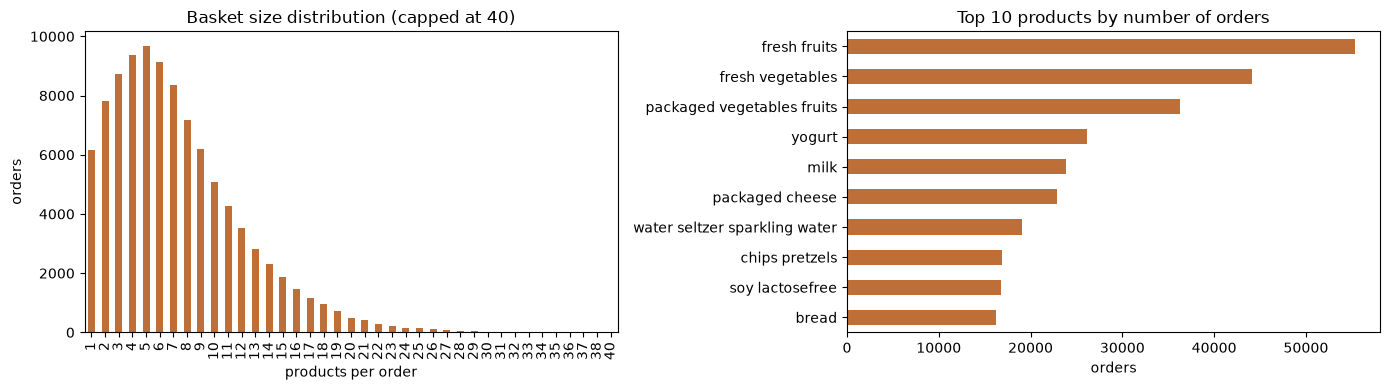

In [4]:
def build_order_baskets(df):
    # {order_id: {product_id, ...}}: one basket per order
    return {int(order_id): set(group["product_id"].dropna().astype(int))
            for order_id, group in df.groupby("order_id")}


def product_lookup(df):
    # {product_id: {"product_name":..., "department":...}} for readable output
    return (df.dropna(subset=["product_id"])
              .sort_values(["product_id", "product_name"])
              .drop_duplicates("product_id")
              .set_index("product_id")[["product_name", "department"]]
              .to_dict(orient="index"))


baskets = build_order_baskets(frame)
lookup = product_lookup(frame)
sizes = pd.Series([len(items) for items in baskets.values()])

display(pd.Series({
    "order lines": len(frame),
    "orders (baskets)": len(baskets),
    "customers": frame["user_id"].nunique(),
    "distinct products": frame["product_id"].nunique(),
    "avg basket size": round(sizes.mean(), 2),
    "median basket size": sizes.median(),
    "orders with >= 2 products (usable for evaluation)": int((sizes >= 2).sum()),
    "reorder rate (%)": round(frame["reordered"].mean() * 100, 1),
}, name="dataset profile"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sizes.clip(upper=40).value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#be6f37")
axes[0].set_title("Basket size distribution (capped at 40)")
axes[0].set_xlabel("products per order"); axes[0].set_ylabel("orders")
top = frame.groupby("product_id")["order_id"].nunique().nlargest(10)
top.index = [lookup[int(i)]["product_name"] for i in top.index]
top.sort_values().plot(kind="barh", ax=axes[1], color="#be6f37")
axes[1].set_title("Top 10 products by number of orders"); axes[1].set_xlabel("orders")
plt.tight_layout(); plt.show()

## 4. Stage 3: Train/test split (leakage-safe)

Users are split **before** any mining. A user's orders never appear in both partitions, so the model cannot memorise a customer's habits and then be "tested" on the same customer. The assertion at the end enforces this.

In [5]:
def split_users(df, *, test_size=TEST_SIZE, seed=SEED):
    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")
    users = df["user_id"].dropna().unique()
    rng = np.random.default_rng(seed)
    test_count = max(1, int(len(users) * test_size)) if len(users) else 0
    test_users = set(rng.choice(users, size=test_count, replace=False).tolist()) if test_count else set()
    is_test = df["user_id"].isin(test_users)
    return df.loc[~is_test].copy(), df.loc[is_test].copy()


train, test = split_users(frame)
train_baskets, test_baskets = build_order_baskets(train), build_order_baskets(test)

assert set(train["user_id"]).isdisjoint(set(test["user_id"])), "user leakage between train and test!"
display(pd.DataFrame({
    "partition": ["train", "test"],
    "users": [train["user_id"].nunique(), test["user_id"].nunique()],
    "orders": [len(train_baskets), len(test_baskets)],
    "order lines": [len(train), len(test)],
}).set_index("partition"))

,users,orders,order lines
partition,,,
train,41797,79102,800262
test,10449,19825,199718


## 5. Stage 4 and 5: Feature encoding (and why there is no scaling)

Apriori needs a boolean matrix: one row per basket, one column per product, `True` if the product is in the basket. `TransactionEncoder` builds it, and it is the equivalent of one-hot encoding in a supervised pipeline.

**Feature scaling is not applicable.** Every feature is already a 0/1 presence flag with the same range, and Apriori counts occurrences rather than measuring distances, so standardising would have no effect.

The encoder is fitted on **training baskets only**.

In [6]:
def encode_baskets(basket_dict):
    transactions = [sorted(items) for items in basket_dict.values() if items]
    encoder = TransactionEncoder()
    matrix = encoder.fit(transactions).transform(transactions)
    return pd.DataFrame(matrix, columns=encoder.columns_)


train_matrix = encode_baskets(train_baskets)
density = train_matrix.to_numpy().mean() * 100
print(f"Training matrix: {train_matrix.shape[0]:,} baskets x {train_matrix.shape[1]:,} products "
      f"({density:.2f}% of cells are True: baskets are sparse)")
train_matrix.iloc[:5, :8]

Training matrix: 79,102 baskets x 134 products (5.43% of cells are True: baskets are sparse)


,1,2,3,4,5,6,7,8
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


## 6. Stage 6: Model training: mining Apriori rules

"Training" for Apriori is two steps, both run on the training baskets only:

1. **`apriori(...)`** finds every itemset that appears in at least `MIN_SUPPORT` of the baskets (frequent itemsets).
2. **`association_rules(...)`** turns those itemsets into rules *A → B* and keeps the ones with confidence ≥ `MIN_CONFIDENCE`.

| metric | meaning |
|---|---|
| support | share of baskets containing A and B together (reach) |
| confidence | P(B in basket \| A in basket) (reliability) |
| lift | confidence ÷ P(B): how much A raises the chance of B vs. its normal popularity (> 1 = real association) |
| leverage | support(A,B) − support(A)·support(B) |

In [7]:
def mine_rules(basket_matrix, *, min_support=MIN_SUPPORT, min_confidence=MIN_CONFIDENCE, max_len=MAX_LEN):
    frequent = apriori(basket_matrix, min_support=min_support, use_colnames=True, max_len=max_len)
    if frequent.empty:
        return frequent, pd.DataFrame(columns=["antecedents", "consequents", "support", "confidence", "lift", "leverage"])
    try:   # newer mlxtend needs the number of baskets
        rules = association_rules(frequent, metric="confidence", min_threshold=min_confidence,
                                  num_itemsets=len(basket_matrix))
    except TypeError:
        rules = association_rules(frequent, metric="confidence", min_threshold=min_confidence)
    rules = rules.sort_values(["lift", "confidence", "support"], ascending=False).reset_index(drop=True)
    return frequent, rules


frequent, rules = mine_rules(train_matrix)

display(pd.Series({
    "training baskets": len(train_matrix),
    "frequent itemsets": len(frequent),
    "association rules": len(rules),
    "min_support": MIN_SUPPORT, "min_confidence": MIN_CONFIDENCE, "max itemset length": MAX_LEN,
}, name="training summary"))
print("Frequent itemsets by length:")
display(frequent["itemsets"].map(len).value_counts().sort_index().rename("itemsets").to_frame())

training baskets      79102.000
frequent itemsets      5687.000
association rules      8791.000
min_support               0.005
min_confidence            0.200
max itemset length        3.000
Name: training summary, dtype: float64

Frequent itemsets by length:


,itemsets
itemsets,
1,119
2,1631
3,3937


In [8]:
def name_rules(rules_df, lookup, n_baskets):
    # readable version of the rule table (product ids -> names)
    def names(ids):
        return " + ".join(lookup[int(i)]["product_name"] for i in sorted(ids))
    out = pd.DataFrame({
        "antecedent": rules_df["antecedents"].apply(names),
        "consequent": rules_df["consequents"].apply(names),
        "orders": (rules_df["support"] * n_baskets).round().astype(int),
        "support %": (rules_df["support"] * 100).round(2),
        "confidence %": (rules_df["confidence"] * 100).round(1),
        "lift": rules_df["lift"].round(2),
        "leverage": rules_df["leverage"].round(4),
    })
    return out


train_lookup = product_lookup(train)
named_rules = name_rules(rules, train_lookup, len(train_matrix))
print("Top 15 rules by lift (one-sided pairs appear twice with the same lift: A->B and B->A):")
display(named_rules.head(15))
print("Rule quality summary:")
display(pd.Series({
    "median confidence %": float(named_rules["confidence %"].median()),
    "median lift": float(named_rules["lift"].median()),
    "rules with lift <= 1": int((rules["lift"] <= 1).sum()),
    "rules with >= 30 supporting orders": int((named_rules["orders"] >= 30).sum()),
}))

Top 15 rules by lift (one-sided pairs appear twice with the same lift: A->B and B->A):


,antecedent,consequent,orders,support %,confidence %,lift,leverage
0,frozen vegan vegetarian,tofu meat alternatives,400,0.51,20.1,5.85,0.0042
1,pasta sauce + bread,dry pasta,535,0.68,39.8,5.56,0.0055
2,bread + dry pasta,pasta sauce,535,0.68,34.5,5.49,0.0055
3,chips pretzels + dry pasta,pasta sauce,467,0.59,33.8,5.37,0.0048
4,canned meals beans + soup broth bouillon,canned jarred vegetables,426,0.54,37.6,5.23,0.0044
5,packaged cheese + dry pasta,pasta sauce,781,0.99,32.9,5.23,0.0080
6,pasta sauce + chips pretzels,dry pasta,467,0.59,36.4,5.08,0.0047
7,pasta sauce + packaged cheese,dry pasta,781,0.99,35.7,4.99,0.0079
8,pasta sauce + milk,dry pasta,552,0.70,35.2,4.92,0.0056
9,packaged vegetables fruits + dry pasta,pasta sauce,882,1.12,30.0,4.77,0.0088


Rule quality summary:


median confidence %                     39.90
median lift                              1.55
rules with lift <= 1                   103.00
rules with >= 30 supporting orders    8791.00
dtype: float64

## 7. Stage 7: Evaluation on held-out users

**Protocol (leave-one-out on every eligible test order):**
1. Take each test order with **≥ 2 products**.
2. Hide one product at random (same seed → same hidden items for every model).
3. Show the model the remaining products and ask for the top *K* recommendations. A rule fires when all its antecedent products are in the visible basket, and the score of a candidate is the highest confidence among the rules that recommend it. Products already in the basket are never recommended.
4. A **hit** means the hidden product is in the top *K*.

| metric | meaning |
|---|---|
| **Hit rate@K** | share of test orders whose hidden product is in the top-K list (the recommender's equivalent of accuracy). With one hidden item per order, recall@K is identical, so it is not reported separately |
| **MRR@K** | mean of 1 ÷ rank of the hidden product (0 if not in top K): rewards ranking it higher |
| **Coverage** | share of test orders where at least one rule produced a usable recommendation |

**Three models are compared:**
- *Popularity baseline*: recommend the best-selling products not already in the basket. This is the bar to beat.
- *Rules only*: only rule-based recommendations; orders where no rule fires count as misses.
- *Rules + popularity fallback*: rule recommendations first, popularity fills the remaining slots.

> **Note on implementation parity.** This evaluation fixes three details compared with `_recommendation_matrix` in `cartsense_analysis.py`: (1) the popularity baseline and fallback now exclude products already in the basket, (2) the top-K list is explicitly sorted before computing MRR, and (3) "rules only" ignores zero-score filler slots and counts coverage only when a rule recommends something *not already in the basket*. Section 9 compares both versions so you can patch the module.

In [9]:
def _top_k_sorted(rank_scores, k):
    # indices and scores of the k best candidates per row, explicitly sorted (best first)
    k = min(k, rank_scores.shape[1])
    part = np.argpartition(-rank_scores, k - 1, axis=1)[:, :k]
    part_scores = np.take_along_axis(rank_scores, part, axis=1)
    order = np.argsort(-part_scores, axis=1, kind="stable")
    return np.take_along_axis(part, order, axis=1), np.take_along_axis(part_scores, order, axis=1)


def _metrics(rank_scores, hidden, ks, *, coverage, rules_only=False):
    top, top_scores = _top_k_sorted(rank_scores, max(ks))
    is_hit = top == hidden[:, None]
    if rules_only:                      # slots without a rule score are not recommendations
        is_hit &= top_scores > 0
    row = {"coveragePercent": round(float(coverage * 100), 2)}
    for k in ks:
        hit_k = is_hit[:, :k].any(axis=1)
        rank = is_hit[:, :k].argmax(axis=1) + 1
        row[f"hitRateAt{k}"] = round(float(hit_k.mean() * 100), 2)
        row[f"mrrAt{k}"] = round(float(np.where(hit_k, 1.0 / rank, 0.0).mean()), 4)
    return row


def evaluate_recommendations(train_df, test_df, rules_df, *, ks=KS, seed=SEED):
    test_b = build_order_baskets(test_df)
    popularity = train_df["product_id"].value_counts(normalize=True).to_dict()

    eligible = [sorted(items) for items in test_b.values() if len(items) >= 2]
    if not eligible:
        raise ValueError("no test order has 2+ products to evaluate")
    products = sorted({p for items in eligible for p in items} | set(popularity))
    idx = {p: i for i, p in enumerate(products)}

    matrix = np.zeros((len(eligible), len(products)), dtype=bool)
    for r, items in enumerate(eligible):
        matrix[r, [idx[p] for p in items]] = True

    # hide one random product per order
    rng = np.random.default_rng(seed)
    hidden = np.array([rng.choice(np.flatnonzero(row)) for row in matrix], dtype=int)
    seen = matrix.copy()
    seen[np.arange(len(eligible)), hidden] = False

    # rule scores: highest confidence among the rules that fire
    rule_scores = np.zeros(matrix.shape, dtype=np.float32)
    for ant, cons, conf in zip(rules_df["antecedents"], rules_df["consequents"], rules_df["confidence"]):
        if len(cons) != 1 or any(a not in idx for a in ant):
            continue            # a multi-item consequent is covered by its own single-item rules
        target = idx[next(iter(cons))]
        fires = seen[:, [idx[a] for a in ant]].all(axis=1)
        rule_scores[fires, target] = np.maximum(rule_scores[fires, target], conf)
    rule_scores[seen] = -np.inf     # never recommend what is already in the basket

    pop_vector = np.array([popularity.get(p, 0.0) for p in products], dtype=np.float32)
    pop_scores = np.where(seen, -np.inf, pop_vector).astype(np.float32)           # baseline
    hybrid_scores = np.where(rule_scores > 0, 1.0 + rule_scores, pop_scores)      # rules outrank fallback
    hybrid_scores[seen] = -np.inf

    rule_coverage = float((rule_scores > 0).any(axis=1).mean())
    table = pd.DataFrame({
        "Popularity baseline": _metrics(pop_scores, hidden, ks, coverage=1.0),
        "Rules only": _metrics(rule_scores, hidden, ks, coverage=rule_coverage, rules_only=True),
        "Rules + popularity fallback": _metrics(hybrid_scores, hidden, ks, coverage=1.0),
    }).T
    info = {"ordersEvaluated": len(eligible), "ruleCoverage": round(rule_coverage * 100, 2),
            "trainOrders": len(build_order_baskets(train_df)), "testOrders": len(test_b)}
    return table, info


eval_table, eval_info = evaluate_recommendations(train, test, rules)
print(f"Evaluated on {eval_info['ordersEvaluated']:,} test orders "
      f"({eval_info['testOrders']:,} test orders in total, users never seen in training)")
display(eval_table)

Evaluated on 18,617 test orders (19,825 test orders in total, users never seen in training)


,coveragePercent,hitRateAt1,mrrAt1,hitRateAt3,mrrAt3,hitRateAt5,mrrAt5,hitRateAt10,mrrAt10
Popularity baseline,100.00,15.91,0.1591,26.61,0.2059,33.24,0.2210,45.68,0.2378
Rules only,99.48,16.17,0.1617,27.02,0.2088,34.30,0.2254,47.24,0.2425
Rules + popularity fallback,100.00,16.21,0.1621,27.09,0.2094,34.38,0.2260,47.79,0.2436


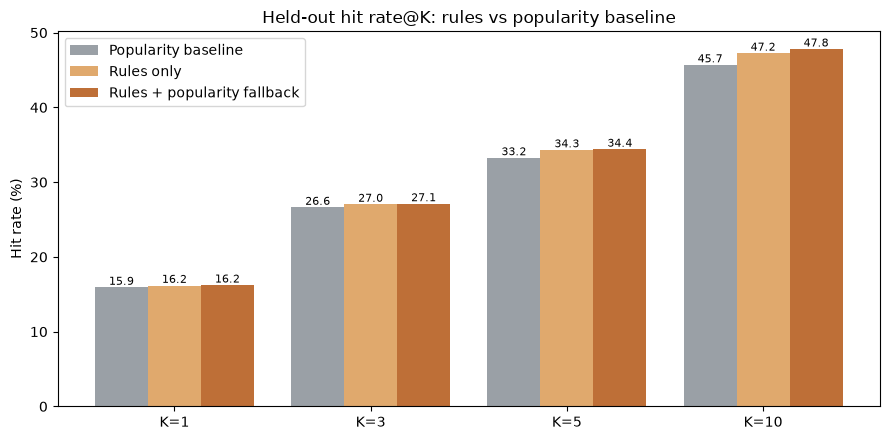

In [10]:
# visual comparison: hit rate@K
fig, ax = plt.subplots(figsize=(9, 4.5))
width = 0.27
x = np.arange(len(KS))
for offset, (name, color) in enumerate([("Popularity baseline", "#9aa0a6"),
                                         ("Rules only", "#e0a96d"),
                                         ("Rules + popularity fallback", "#be6f37")]):
    values = [eval_table.loc[name, f"hitRateAt{k}"] for k in KS]
    bars = ax.bar(x + (offset - 1) * width, values, width, label=name, color=color)
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f"K={k}" for k in KS])
ax.set_ylabel("Hit rate (%)"); ax.set_title("Held-out hit rate@K: rules vs popularity baseline")
ax.legend(); plt.tight_layout(); plt.show()

### Success criteria (declare before looking at the numbers)

Apriori has no accuracy target, so the pass/fail rule is defined for what a recommender must do:

1. **Beat the popularity baseline** in hit rate at **every** K in `KS` (this is the real proof that the rules add value).
2. **Cover enough orders** that the rules matter in practice (`MIN_RULE_COVERAGE`, set it before you run).
3. **Hold up across splits**: the gain stays positive in every random seed (Section 8).

In [11]:
MIN_RULE_COVERAGE = 50.0    # % of test orders that must receive at least one rule-based recommendation

def check_success(table, info, ks=KS, min_coverage=MIN_RULE_COVERAGE):
    rows = []
    for k in ks:
        base = table.loc["Popularity baseline", f"hitRateAt{k}"]
        model = table.loc["Rules + popularity fallback", f"hitRateAt{k}"]
        rows.append({"K": k, "baseline hit %": base, "rules + fallback hit %": model,
                     "gain (pts)": round(model - base, 2), "relative": f"{model / base:.2f}x" if base else "n/a",
                     "beats baseline": model > base})
    out = pd.DataFrame(rows).set_index("K")
    passed = bool(out["beats baseline"].all()) and info["ruleCoverage"] >= min_coverage
    return out, passed

criteria, passed = check_success(eval_table, eval_info)
display(criteria)
print(f"Rule coverage: {eval_info['ruleCoverage']}% (required >= {MIN_RULE_COVERAGE}%)")
print("RESULT:", "PASS" if passed else "FAIL")

,baseline hit %,rules + fallback hit %,gain (pts),relative,beats baseline
K,,,,,
1,15.91,16.21,0.30,1.02x,True
3,26.61,27.09,0.48,1.02x,True
5,33.24,34.38,1.14,1.03x,True
10,45.68,47.79,2.11,1.05x,True


Rule coverage: 99.48% (required >= 50.0%)
RESULT: PASS


## 8. The pipeline as one function, plus multi-seed stability

`run_pipeline` chains the stages: **split → encode → train → evaluate**. It is called once per random seed, so the result is reported as *mean ± std* instead of depending on one lucky split. (Loading and validation run once because they do not depend on the seed.)

> Each seed re-splits the users and re-mines the rules, so on the 1M-row dataset this cell is slow. Use the 20k or 100k set while developing, or set `SEEDS = (SEED,)`.

In [12]:
def run_pipeline(clean_frame, *, seed=SEED, test_size=TEST_SIZE, min_support=MIN_SUPPORT,
                 min_confidence=MIN_CONFIDENCE, max_len=MAX_LEN, ks=KS):
    train_df, test_df = split_users(clean_frame, test_size=test_size, seed=seed)       # stage 3
    matrix = encode_baskets(build_order_baskets(train_df))                             # stage 4
    frequent_sets, rule_table = mine_rules(matrix, min_support=min_support,            # stage 6
                                           min_confidence=min_confidence, max_len=max_len)
    table, info = evaluate_recommendations(train_df, test_df, rule_table, ks=ks, seed=seed)   # stage 7
    return {"seed": seed, "train": train_df, "test": test_df, "frequent": frequent_sets,
            "rules": rule_table, "table": table, "info": info}


SEEDS = (42, 7, 21, 99, 123)
runs = []
for s in SEEDS:
    result = run_pipeline(frame, seed=s)
    for k in KS:
        runs.append({"seed": s, "K": k,
                     "baseline": result["table"].loc["Popularity baseline", f"hitRateAt{k}"],
                     "rules only": result["table"].loc["Rules only", f"hitRateAt{k}"],
                     "rules + fallback": result["table"].loc["Rules + popularity fallback", f"hitRateAt{k}"],
                     "rules": len(result["rules"]), "rule coverage %": result["info"]["ruleCoverage"]})
    print(f"seed {s}: {len(result['rules']):,} rules, rule coverage {result['info']['ruleCoverage']}%")

runs = pd.DataFrame(runs)
runs["gain (pts)"] = runs["rules + fallback"] - runs["baseline"]
summary = runs.groupby("K")[["baseline", "rules only", "rules + fallback", "gain (pts)"]].agg(["mean", "std"]).round(2)
print("\nHit rate % across seeds (mean, std):")
display(summary)
print("Gain positive for every seed and every K:", bool((runs["gain (pts)"] > 0).all()))

seed 42: 8,791 rules, rule coverage 99.48%
seed 7: 8,855 rules, rule coverage 99.39%
seed 21: 8,781 rules, rule coverage 99.49%
seed 99: 8,807 rules, rule coverage 99.4%
seed 123: 8,768 rules, rule coverage 99.4%

Hit rate % across seeds (mean, std):


baseline       rules only       rules + fallback       gain (pts)      
       mean   std       mean   std             mean   std       mean   std
K                                                                         
1     16.33  0.37      16.59  0.32            16.63  0.33       0.29  0.04
3     27.14  0.45      27.58  0.44            27.65  0.45       0.51  0.04
5     33.85  0.54      34.76  0.41            34.85  0.42       1.00  0.20
10    46.43  0.55      47.60  0.37            48.23  0.38       1.80  0.24

Gain positive for every seed and every K: True


## 9. Parity check against the production module

The dashboard uses `cartsense_analysis.py`. This cell runs the production functions on the **same train/test split** and verifies that mining gives identical rules. It also shows the production evaluation next to the one in this notebook, so the effect of the fixes in Section 7 is visible.

If the module is not importable from this folder, the cell prints a message and the rest of the notebook still stands on its own.

In [13]:
try:
    import cartsense_analysis as prod
except ImportError as exc:
    print("cartsense_analysis not importable from here, skipping parity check:", exc)
else:
    # same split (same seed) -> same training baskets
    prod_rules, prod_trace = prod.mine_association_rules(train, min_support=MIN_SUPPORT,
                                                         min_confidence=MIN_CONFIDENCE, max_len=MAX_LEN)
    ours = {(tuple(sorted(a)), tuple(sorted(c))) for a, c in zip(rules["antecedents"], rules["consequents"])}
    theirs = {(tuple(i["productId"] for i in r["antecedent"]), tuple(i["productId"] for i in r["consequent"]))
              for r in prod_rules}
    print(f"rules: notebook {len(ours):,} | production {len(theirs):,} | identical rule set: {ours == theirs}")
    assert ours == theirs, "mining differs between notebook and production module"

    prod_eval = prod.evaluate_recommendations(train, test, prod_rules, ks=KS, seed=SEED)
    compare = pd.DataFrame({
        "production: popularity baseline": prod_eval["popularityBaseline"],
        "notebook:   popularity baseline": eval_table.loc["Popularity baseline"],
        "production: rules + fallback": prod_eval["rulesWithPopularityFallback"],
        "notebook:   rules + fallback": eval_table.loc["Rules + popularity fallback"],
    }).T[["coveragePercent"] + [f"hitRateAt{k}" for k in KS] + [f"mrrAt{k}" for k in KS]]
    display(compare)

rules: notebook 8,791 | production 8,791 | identical rule set: True


,coveragePercent,hitRateAt1,hitRateAt3,hitRateAt5,hitRateAt10,mrrAt1,mrrAt3,mrrAt5,mrrAt10
production: popularity baseline,100.0,9.00,20.39,26.88,40.32,0.0900,0.1385,0.1533,0.1712
notebook: popularity baseline,100.0,15.91,26.61,33.24,45.68,0.1591,0.2059,0.2210,0.2378
production: rules + fallback,100.0,16.21,27.09,34.38,47.62,0.1621,0.2094,0.2260,0.2434
notebook: rules + fallback,100.0,16.21,27.09,34.38,47.79,0.1621,0.2094,0.2260,0.2436
